# LAB3 - Phần 2 - Bài 6

Sử dụng thuật toán k-Means để giảm số màu trong ảnh, từ đó giảm kích thước file ảnh. Mỗi pixel là một điểm dữ liệu 3 chiều (R, G, B); k-Means gom các pixel thành k cụm và thay màu của mỗi pixel bằng màu tâm cụm của nó, nên ảnh kết quả chỉ còn k màu.

## 1. Khai báo thư viện

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'   # tránh cảnh báo memory leak của KMeans trên Windows

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
%matplotlib inline

IMAGE_PATH = './Dataset/flower.png'   # ảnh cần giảm kích thước
OUTPUT_DIR = './Bai6_26_png'
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Đọc ảnh và hiển thị ra màn hình

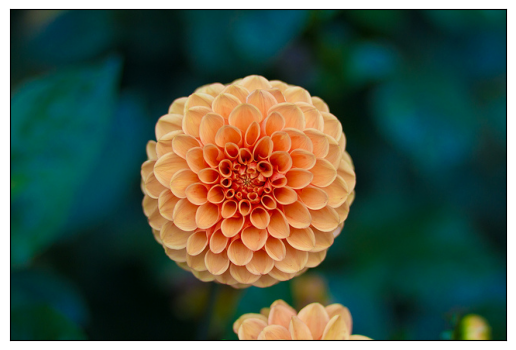

In [2]:
image = Image.open(IMAGE_PATH).convert('RGB')
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.show()

Đặng Phan Duy - 6451071010

## 3. Chuyển ảnh thành mảng số, lấy chiều rộng, cao của ảnh

In [3]:
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]
print("Image shape:", imarr.shape, "- rows:", rows, "- cols:", cols)

# Số màu khác nhau trong ảnh gốc
n_colors_original = len(np.unique(imarr.reshape(-1, 3), axis=0))
print("Số màu khác nhau trong ảnh gốc:", n_colors_original)

Image shape: (427, 640, 3) - rows: 427 - cols: 640
Số màu khác nhau trong ảnh gốc: 62941


Đặng Phan Duy - 6451071010

## 4. Chuẩn hóa giá trị màu về [0, 1] và chuyển mảng 3 chiều thành 2 chiều

In [4]:
data = imarr / 255.0 # use 0...1 scale
data = data.reshape(rows * cols, 3)
data.shape

(273280, 3)

Đặng Phan Duy - 6451071010

## 5. Gom cụm với số màu mong muốn là 32

In [5]:
kmeans = KMeans(n_clusters = 32, max_iter=300, random_state=42)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]
print("new_colors shape:", new_colors.shape)
print("Số màu khác nhau sau khi gom cụm:", len(np.unique(new_colors, axis=0)))

new_colors shape: (273280, 3)
Số màu khác nhau sau khi gom cụm: 32


Đặng Phan Duy - 6451071010

## 6. Khôi phục mảng 2 chiều thành 3 chiều như ban đầu

In [6]:
img_recolored = new_colors.reshape(imarr.shape)
img_recolored.shape

(427, 640, 3)

Đặng Phan Duy - 6451071010

## 7. Hiển thị ảnh kết quả và so sánh với ảnh gốc

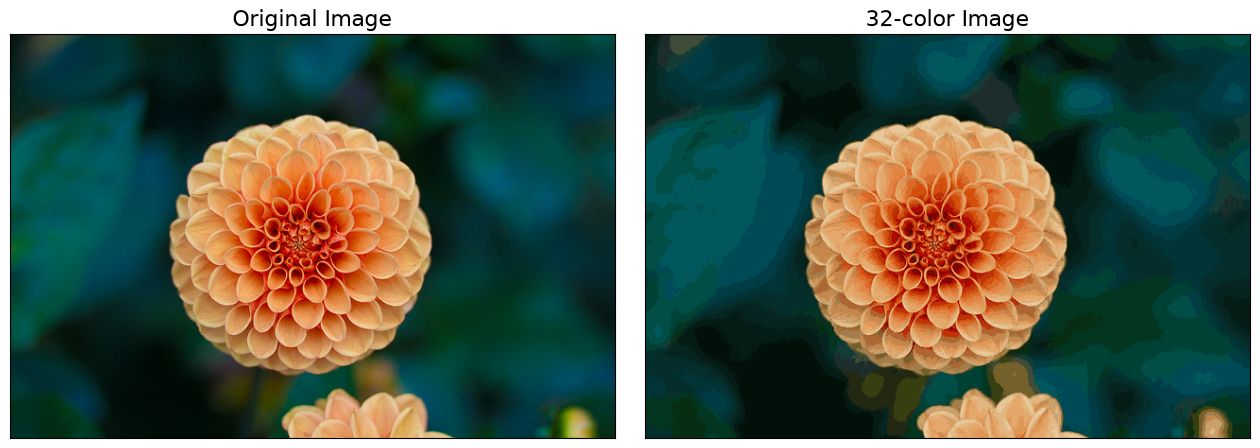

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(img_recolored)
ax[1].set_title('32-color Image', size=16);

Đặng Phan Duy - 6451071010

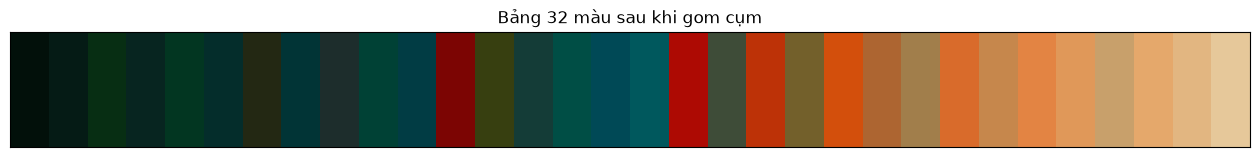

In [8]:
# Bảng 32 màu (tâm cụm) mà k-Means tìm được
palette = kmeans.cluster_centers_
order = np.argsort(palette.sum(axis=1))
plt.figure(figsize=(16, 1.5))
plt.imshow(palette[order][np.newaxis, :, :], aspect='auto')
plt.xticks([]), plt.yticks([])
plt.title('Bảng 32 màu sau khi gom cụm')
plt.show()

Đặng Phan Duy - 6451071010

## 8. Lưu ảnh kết quả xuống đĩa cứng

In [9]:
img_recolored = img_recolored * 255
new_img = Image.fromarray(img_recolored.astype(np.uint8))
new_img.save(os.path.join(OUTPUT_DIR, 'compressed_img2.png'))

# Lưu thêm dạng ảnh bảng màu (palette, mode 'P'): mỗi pixel chỉ lưu chỉ số màu (1 byte) thay vì 3 byte RGB
def save_palette(labels, centers, path):
    # ảnh mode 'P': lưu chỉ số cụm của từng pixel + bảng màu là các tâm cụm
    img = Image.fromarray(labels.reshape(rows, cols).astype(np.uint8), mode='P')
    img.putpalette((centers * 255).round().astype(np.uint8).ravel().tolist())
    img.save(path)

save_palette(kmeans.predict(data), kmeans.cluster_centers_, os.path.join(OUTPUT_DIR, 'compressed_img2_palette.png'))

# Lưu ảnh gốc theo cùng định dạng PNG để so sánh công bằng
image.save(os.path.join(OUTPUT_DIR, 'original.png'))

sizes = pd.DataFrame({
    'File': ['original.png', 'compressed_img2.png', 'compressed_img2_palette.png'],
    'Số màu': [n_colors_original, 32, 32],
    'Kích thước (KB)': [os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1024
                        for f in ['original.png', 'compressed_img2.png', 'compressed_img2_palette.png']]
})
sizes['Tỷ lệ so với ảnh gốc'] = sizes['Kích thước (KB)'] / sizes['Kích thước (KB)'][0]
sizes

,File,Số màu,Kích thước (KB),Tỷ lệ so với ảnh gốc
0,original.png,62941,345.209961,1.000000
1,compressed_img2.png,32,85.215820,0.246852
2,compressed_img2_palette.png,32,41.134766,0.119159


Đặng Phan Duy - 6451071010

## 9. Thử với các số màu khác nhau

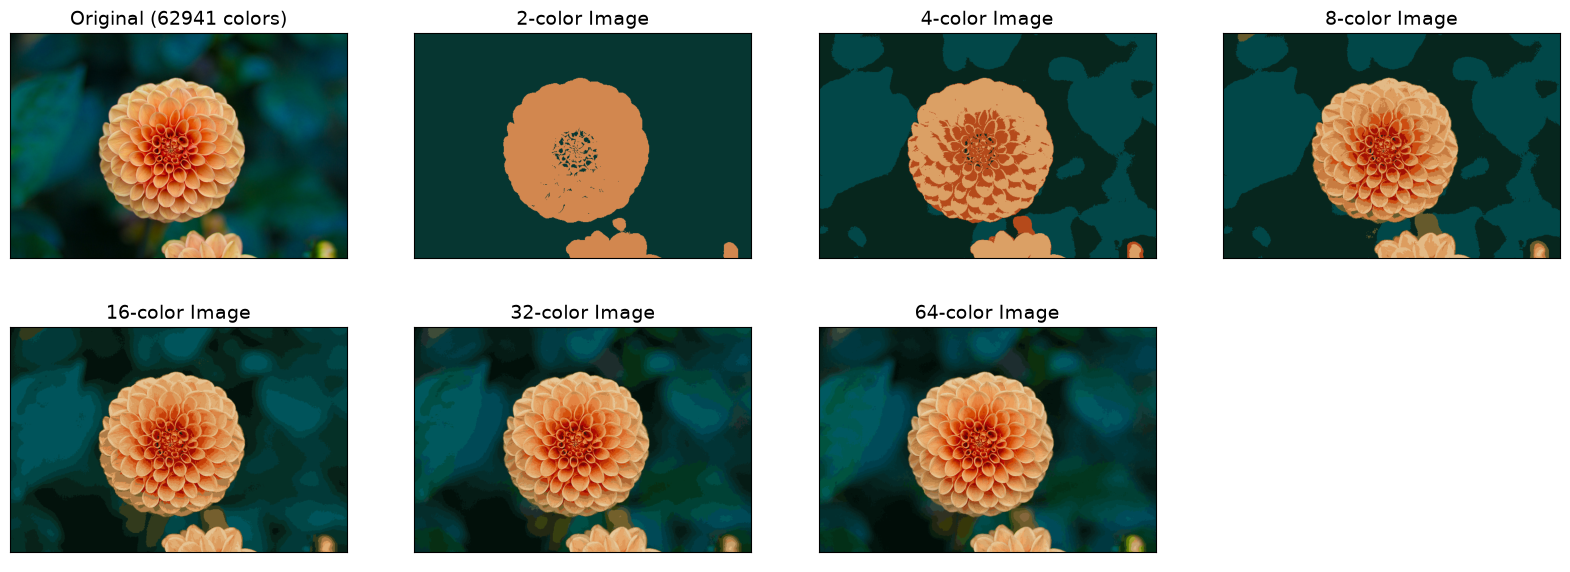

,Số màu (k),Inertia,MSE so với ảnh gốc,Kích thước file palette (KB)
0,2,9064.219826,0.011056,2.684570
1,4,3717.568577,0.004535,9.949219
2,8,2202.646546,0.002687,20.374023
3,16,908.037418,0.001108,33.992188
4,32,536.214027,0.000654,41.134766
5,64,317.605070,0.000387,55.847656


In [10]:
k_list = [2, 4, 8, 16, 32, 64]
results = []
fig, ax = plt.subplots(2, 4, figsize=(20, 7), subplot_kw=dict(xticks=[], yticks=[]))
ax = ax.ravel()
ax[0].imshow(image)
ax[0].set_title('Original ({0} colors)'.format(n_colors_original), size=14)

for i, k in enumerate(k_list):
    km = KMeans(n_clusters=k, max_iter=300, random_state=42).fit(data)
    recolored = km.cluster_centers_[km.labels_].reshape(imarr.shape)

    path = os.path.join(OUTPUT_DIR, 'compressed_{0}_colors.png'.format(k))
    save_palette(km.labels_, km.cluster_centers_, path)

    mse = np.mean((recolored - data.reshape(imarr.shape)) ** 2)
    results.append([k, km.inertia_, mse, os.path.getsize(path) / 1024])

    ax[i + 1].imshow(recolored)
    ax[i + 1].set_title('{0}-color Image'.format(k), size=14)
ax[-1].axis('off')
plt.show()

results = pd.DataFrame(results, columns=['Số màu (k)', 'Inertia', 'MSE so với ảnh gốc', 'Kích thước file palette (KB)'])
results

Đặng Phan Duy - 6451071010

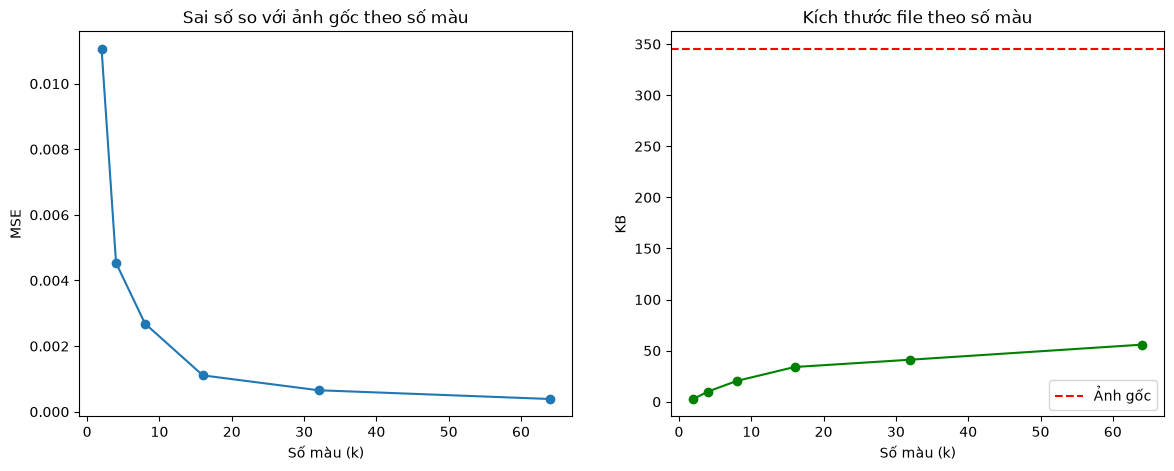

In [11]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(results['Số màu (k)'], results['MSE so với ảnh gốc'], 'o-')
plt.xlabel('Số màu (k)'), plt.ylabel('MSE')
plt.title('Sai số so với ảnh gốc theo số màu')

plt.subplot(1, 2, 2)
plt.plot(results['Số màu (k)'], results['Kích thước file palette (KB)'], 'o-', color='green')
plt.axhline(sizes['Kích thước (KB)'][0], color='red', linestyle='--', label='Ảnh gốc')
plt.xlabel('Số màu (k)'), plt.ylabel('KB')
plt.title('Kích thước file theo số màu')
plt.legend()
plt.show()

Đặng Phan Duy - 6451071010

## 10. Nhận xét

Nhận xét:

- Ảnh gốc có 62941 màu khác nhau. Sau khi gom cụm bằng k-Means với k = 32, ảnh chỉ còn 32 màu (là 32 tâm cụm) nhưng bông hoa vẫn giữ được hình dạng, chi tiết cánh hoa và màu sắc gần như ảnh gốc. Khác biệt chủ yếu thấy ở vùng nền xanh mờ (vốn chuyển màu mượt) bị phân thành các mảng màu có ranh giới (hiện tượng banding).
- Kích thước file giảm đáng kể: ảnh gốc PNG ≈ 345 KB; ảnh 32 màu lưu dạng RGB (như hướng dẫn) ≈ 85 KB (≈ 25% ảnh gốc) do có ít màu nên PNG nén tốt hơn; nếu lưu dạng ảnh bảng màu (palette) thì mỗi pixel chỉ cần lưu chỉ số cụm (1 byte thay vì 3 byte) nên chỉ còn ≈ 41 KB (≈ 12% ảnh gốc).
- Khi tăng số màu k: inertia và sai số MSE so với ảnh gốc giảm (ảnh đẹp hơn) nhưng kích thước file tăng. Với k = 2, 4 ảnh mất gần hết chi tiết; với k = 8 đã nhận ra rõ bông hoa nhưng nền bị phân mảng mạnh; từ k = 16 - 32 trở lên chất lượng ảnh khá tốt bằng mắt thường. Đường MSE giảm chậm lại sau k = 16 - 32, nên k = 32 là lựa chọn cân bằng giữa chất lượng ảnh và kích thước file.
- Đây là phương pháp nén mất mát (lossy): màu của mỗi pixel bị thay bằng màu tâm cụm gần nhất nên không thể khôi phục chính xác ảnh gốc. Thời gian chạy k-Means tăng theo số pixel và số cụm k.